# BB84 Quantum Key Distribution with Qiskit
**IBM Qiskit Fall Fest 2026 – RV University Hackathon**

All results in this notebook come from the **Qiskit Aer simulator** – (not real quantum hardware).

**Story:** Alice wants to share a secret key with Bob but Eve is trying to spy on the qubits. I will be demonstrating that Eve's spying leaves a fingerprint – (a ~25% error rate) – that Alice and Bob can detect.

## 1. The idea in plain words
- Alice picks a random **bit** and a random **basis** (Z or X) for each qubit and sends it to Bob.
- Bob measures each qubit in his own random basis.
- They publicly announce their **bases** (never the bits) and keep only positions where the bases matched (~50%). This is *sifting*.
- If nobody spied, the sifted keys are **identical**. 
- If Eve measures in a wrong basis she disturbs the qubit (quantum measurement can't be undone), so Bob gets errors. Eve guesses the right basis half the time, and when she's wrong Bob errs half the time: 0.5 × 0.5 = **25% errors**.

## 2. Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import bb84   # our code in bb84.py

Matplotlib is building the font cache; this may take a moment.


## 3. The circuit
Each qubit is prepared with **X** (bit = 1) and/or **H** (basis = X), then measured (with an **H** first if Bob uses the X basis). Here is a 4-qubit example – Alice sends bits `0,1,1,0` using bases `Z,Z,X,X`, and Bob measures in bases `Z,X,X,Z`.

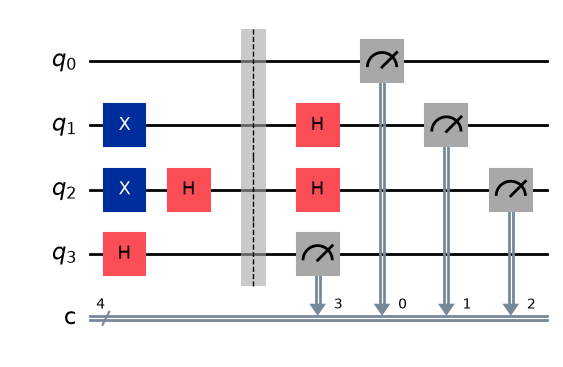

In [3]:
qc = bb84.build_circuit(bits=[0,1,1,0], prep_bases=[0,0,1,1], meas_bases=[0,1,1,0])
qc.draw("mpl")

Reading the diagram: 
- `q0`: Z basis both sides → Bob reads Alice's bit reliably.
- `q1`: Alice used Z, Bob used X → bases differ, Bob's result is random (discarded in sifting).
- `q2`: X basis both sides (X then H on Alice's side, H on Bob's side) → reliable.
- `q3`: bases differ again → random, discarded.

## 4. Run 1 – no eavesdropper

In [4]:
clean = bb84.run_bb84(n=1000, eve=False, seed=42)
print("Qubits sent        :", clean["n"])
print("Sifted key length  :", len(clean["alice_key"]))
print("Error rate         :", f"{clean['error_rate']*100:.2f}%")
print("Alice:", "".join(map(str, clean["alice_key"][:30])))
print("Bob  :", "".join(map(str, clean["bob_key"][:30])))

Qubits sent        : 1000
Sifted key length  : 501
Error rate         : 0.00%
Alice: 000111101011100011101100011110
Bob  : 000111101011100011101100011110


**Meaning:** the keys are identical – Alice and Bob now share a secret key (in a perfect world).

## 5. Run 2 – Eve intercepts every qubit

In [5]:
attacked = bb84.run_bb84(n=1000, eve=True, seed=42)
print("Sifted key length  :", len(attacked["alice_key"]))
print("Error rate         :", f"{attacked['error_rate']*100:.2f}%  (theory: 25%)")
print("Alice:", "".join(map(str, attacked["alice_key"][:30])))
print("Bob  :", "".join(map(str, attacked["bob_key"][:30])))

Sifted key length  : 501
Error rate         : 25.35%  (theory: 25%)
Alice: 000111101011100011101100011110
Bob  : 001011100001100110111100010111


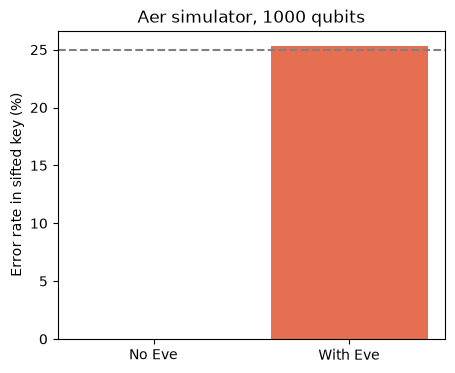

In [6]:
fig, ax = plt.subplots(figsize=(5,4))
vals = [clean["error_rate"]*100, attacked["error_rate"]*100]
ax.bar(["No Eve","With Eve"], vals, color=["#2a9d8f","#e76f51"])
ax.axhline(25, ls="--", color="gray")
ax.set_ylabel("Error rate in sifted key (%)")
ax.set_title("Aer simulator, 1000 qubits")
plt.show()

**Meaning:** Eve's interference is visible as roughly 25% errors, so Alice and Bob would abort.

## 6. How many bits must Alice and Bob compare?
They sacrifice `k` random sifted bits and compare them publicly. Each compared bit has a 25% chance of exposing Eve, so the chance she is caught is $1-(3/4)^k$.

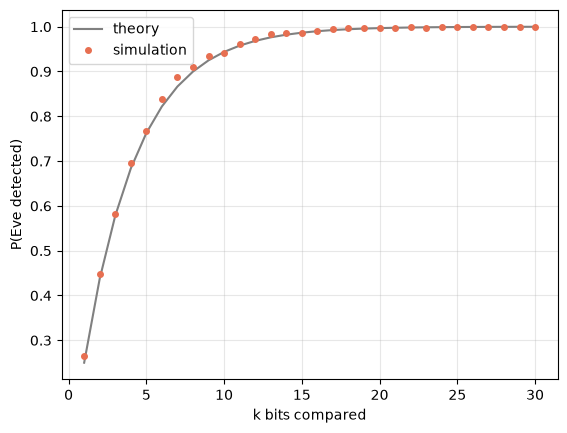

k=20 bits -> detection probability ~ 0.9968


In [7]:
ks = np.arange(1, 31)
sim = [bb84.detection_probability(attacked["alice_key"], attacked["bob_key"], int(k)) for k in ks]
plt.plot(ks, [bb84.theory_detection(k) for k in ks], color="gray", label="theory")
plt.plot(ks, sim, "o", color="#e76f51", ms=4, label="simulation")
plt.xlabel("k bits compared"); plt.ylabel("P(Eve detected)"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
print("k=20 bits -> detection probability ~", round(bb84.theory_detection(20), 4))

**Meaning:** comparing only ~20 bits already catches Eve about 99.7% of the time.

## 7. What if Eve only listens to some qubits?

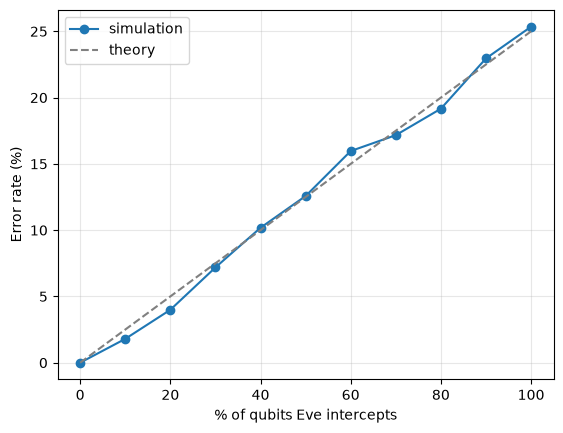

In [8]:
fracs = np.linspace(0, 1, 11)
errs = [bb84.run_bb84(n=1000, eve=True, eve_fraction=f, seed=42)["error_rate"]*100 for f in fracs]
plt.plot(fracs*100, errs, "o-", label="simulation")
plt.plot(fracs*100, fracs*25, "--", color="gray", label="theory")
plt.xlabel("% of qubits Eve intercepts"); plt.ylabel("Error rate (%)"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Meaning:** the error rate scales with how much Eve listens – she can't spy *and* stay hidden.

## 8. Bonus: a noisy channel, no Eve
Real channels aren't perfect. I add a 3% measurement-flip noise and see errors even without Eve.

In [9]:
noisy = bb84.run_bb84(n=2000, eve=False, noise=0.03, seed=42)
print(f"Error rate with 3% noise and NO Eve: {noisy['error_rate']*100:.2f}%")

Error rate with 3% noise and NO Eve: 2.90%


## 9. Limitations and what I learned
**Limitations**
- This is a **simulation**: no real photons, hardware, or hardware noise beyond a simple flip model.
- I only model one attack (intercept-resend). Real security proofs cover all attacks.
- **Noise vs. Eve:** a real system can't tell noise from an attacker, so it uses an error threshold (about 11% is the commonly cited bound for BB84) plus error correction and privacy amplification, which I did not implement.
- Alice and Bob must also use an authenticated classical channel.

**What I learned**
- Measuring a qubit in the wrong basis changes it – that is what makes eavesdropping detectable.
- A simple 4-line circuit idea (X, H, measure) is enough to encode all four BB84 states.
- Reproducible seeds make quantum simulations testable like normal code.

**Next steps:** add error correction (e.g. Cascade) and privacy amplification, other attacks, and a tiny run on real IBM hardware (labelled separately).